# 영화 관객수 예측 — 회귀 분석

ESAA YB 미니 프로젝트(3) · YB 2조

미니 프로젝트(1)에서 EDA했던 데이터콘 **영화 관객수 예측 경진대회** 데이터에 회귀를 적용한다.
train 600편의 정보로 test 243편의 관객수를 맞히는 문제이고, 평가 지표는 **RMSE**다.

## 결과

| 제출 | 구성 | 리더보드 RMSE |
|---|---|---|
| 1 | CatBoost 베이스라인 | 1,202,747 |
| 2 | + 배급사 표기 정규화 | 1,245,912 |
| 3 | + 감독 과거작 실적 | 1,185,603 |
| 4 | 3에서 배급사 정규화 제거 | **1,148,127** |
| 5 | + 흥행작 배수 보정 | 1,142,462 |
| 6 | + KOBIS 실제 기록 (공개 데이터) | **88,582** |

**이 노트북의 중심은 6번이 아니라 1~5번이다.** 6번은 대회 규칙이 허용하는 공공 데이터를
붙인 결과라 점수는 높지만 회귀가 한 일이 적다. 1~5번에서 배운 것을 먼저 쓰고, 6번은 마지막에 둔다.

## 이 프로젝트에서 배운 것

**교차검증이 두 번 다 방향을 거꾸로 알려줬다.** 배급사 표기 정규화는 CV에서 좋아졌는데
리더보드에서 나빠졌고(1,202,747 → 1,245,912), 감독 과거작 실적은 CV에서 나빠졌는데
리더보드에서 좋아졌다(1,245,912 → 1,185,603). 이유는 뒤에서 숫자로 보인다.


In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
import matplotlib.font_manager as fm
_have = {f.name for f in fm.fontManager.ttflist}
for _f in ('Malgun Gothic', 'NanumGothic', 'AppleGothic', 'Gulim'):
    if _f in _have:
        mpl.rcParams['font.family'] = _f
        break
mpl.rcParams['axes.unicode_minus'] = False

RAW = 'https://raw.githubusercontent.com/sjlee53/ESAA-submission/YB/project/1/data/'
LOCAL = os.path.join('..', '1', 'data')

def read(name):
    p = os.path.join(LOCAL, name)
    return pd.read_csv(p) if os.path.exists(p) else pd.read_csv(RAW + name)

train, test, sub = read('movies_train.csv'), read('movies_test.csv'), read('submission.csv')
print('train', train.shape, ' test', test.shape)
train.head(3)


train (600, 12)  test (243, 11)


,title,distributor,genre,release_time,time,screening_rat,director,dir_prev_bfnum,dir_prev_num,num_staff,num_actor,box_off_num
0,개들의 전쟁,롯데엔터테인먼트,액션,2012-11-22,96,청소년 관람불가,조병옥,NaN,0,91,2,23398
1,내부자들,(주)쇼박스,느와르,2015-11-19,130,청소년 관람불가,우민호,1161602.50,2,387,3,7072501
2,은밀하게 위대하게,(주)쇼박스,액션,2013-06-05,123,15세 관람가,장철수,220775.25,4,343,4,6959083


## 1. 타깃의 모양부터 본다

관객수는 **1명부터 1,426만 명까지** 퍼져 있다. 평균 708,182명인데 중앙값은 12,591명이다.
평균이 중앙값의 56배다.


count           600
mean        708,182
std       1,828,006
min               1
25%           1,297
50%          12,591
75%         479,887
max      14,262,766


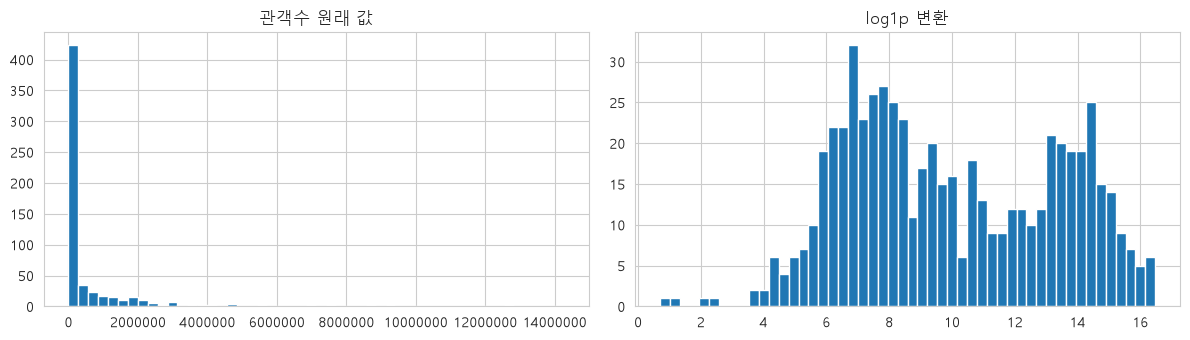

In [2]:
y_all = train['box_off_num']
print(y_all.describe().apply(lambda v: format(v, ',.0f')).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(y_all, bins=50); axes[0].set_title('관객수 원래 값')
axes[0].ticklabel_format(style='plain', axis='x')
axes[1].hist(np.log1p(y_all), bins=50); axes[1].set_title('log1p 변환')
plt.tight_layout(); plt.show()


오른쪽으로 길게 늘어진 분포다. 5장 실습의 자전거 `count`, 주택 `SalePrice`와 같은 모양이고,
같은 처방이 통한다 — **로그를 씌워 학습하고 `expm1`로 되돌린다.**

이 분포가 이 대회의 성격을 결정한다. **RMSE는 제곱 오차라서 큰 영화 몇 편이 점수를 지배한다.**


In [3]:
# 상위 10편이 전체 제곱합에서 차지하는 비중
sq = np.sort(y_all.values.astype(float) ** 2)
print('전체 제곱합 중 상위 10편 비중: {:.1%}'.format(sq[-10:].sum() / sq.sum()))
train.nlargest(5, 'box_off_num')[['title', 'genre', 'num_staff', 'box_off_num']]


전체 제곱합 중 상위 10편 비중: 56.5%


,title,genre,num_staff,box_off_num
372,국제시장,드라마,869,14262766
362,도둑들,느와르,462,12983841
530,7번방의 선물,코미디,300,12811435
498,암살,액션,628,12706663
460,"광해, 왕이 된 남자",드라마,402,12323595


## 2. 전처리

test까지 함께 본 EDA(`1124_ESAA_YB_movie_test_EDA.ipynb`)에서 정한 규칙을 그대로 쓴다.

| 항목 | 결정 | 근거 |
|---|---|---|
| `dir_prev_bfnum` 결측 | 0으로 채우고 `has_prev` 추가 | 결측 100%가 `dir_prev_num == 0` = 이전작 없음 |
| test `time = 2015` | 장르 중앙값 83분으로 교체 | 상영시간 칸에 개봉연도가 들어간 입력 오류 |
| 198분·40분 | 그대로 둔다 | 범위 밖일 뿐 오류가 아니다 |
| `num_staff = 0` | 그대로 둔다 | 소규모 영화 신호 (관객 중앙값 996명) |
| 감독 | 범주로는 쓰지 않는다 | test 63%가 train에 없는 감독 |
| 배급사 | 빈도 인코딩 | 이름을 몰라도 '규모'는 알 수 있다 |
| 장르·등급 | 원-핫 | 범주 12개·4개, test 미등장 0% |


In [4]:
# 타깃을 쓰지 않는 변환만 한다. 그래서 train/test 를 함께 처리해도 누수가 아니다.
def make_features(train, test):
    time_median = train.groupby('genre')['time'].median()
    te = test.copy()
    bad = te['time'] > 200                       # 「슈퍼레이서 엔지」 2015분
    te.loc[bad, 'time'] = te.loc[bad, 'genre'].map(time_median).values

    full = pd.concat([train.drop(columns=['box_off_num']), te], ignore_index=True)
    n = len(train)

    X = pd.DataFrame(index=full.index)
    X['time'] = full['time']
    X['num_staff'] = full['num_staff']
    X['num_actor'] = full['num_actor']
    X['dir_prev_num'] = full['dir_prev_num']
    X['dir_prev_bfnum'] = full['dir_prev_bfnum'].fillna(0)
    X['has_prev'] = (full['dir_prev_num'] > 0).astype(int)

    t = pd.to_datetime(full['release_time'])
    X['year'], X['month'] = t.dt.year, t.dt.month

    X = pd.concat([X,
                   pd.get_dummies(full['genre'], prefix='genre').astype(int),
                   pd.get_dummies(full['screening_rat'], prefix='rat').astype(int)], axis=1)
    X['dist_freq'] = full['distributor'].map(full['distributor'].value_counts()).values

    return X.iloc[:n].reset_index(drop=True), X.iloc[n:].reset_index(drop=True)

X, X_test = make_features(train, test)
y = train['box_off_num'].values
print('피처 {}개'.format(X.shape[1]))
print(list(X.columns[:10]), '...')


피처 25개
['time', 'num_staff', 'num_actor', 'dir_prev_num', 'dir_prev_bfnum', 'has_prev', 'year', 'month', 'genre_SF', 'genre_공포'] ...


## 3. 검증 설계

5-fold를 **시드 세 개로 반복**한다. 폴드마다 흥행작이 어디 들어가느냐로 점수가 크게 흔들리기 때문이다.


In [5]:
SEEDS = (0, 1, 2)

def evaluate(model_fn, X, y, log=True, seeds=SEEDS, name=''):
    scores = []
    for s in seeds:
        for a, b in KFold(5, shuffle=True, random_state=s).split(X):
            m = model_fn(s)
            m.fit(X.iloc[a], np.log1p(y[a]) if log else y[a])
            p = m.predict(X.iloc[b])
            if log:
                p = np.expm1(p)
            scores.append(np.sqrt(np.mean((y[b] - np.clip(p, 0, None)) ** 2)))
    mu, sd = float(np.mean(scores)), float(np.std(scores))
    print('{:<22s} RMSE {:>12,.0f}   (폴드 표준편차 {:>9,.0f})'.format(name, mu, sd))
    return mu, sd

MODELS = {
    'Ridge': lambda s: Ridge(alpha=1.0),
    'RandomForest': lambda s: RandomForestRegressor(n_estimators=500, random_state=s, n_jobs=-1),
    'ExtraTrees': lambda s: ExtraTreesRegressor(n_estimators=500, random_state=s, n_jobs=-1),
    'XGBoost': lambda s: XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                      subsample=0.8, colsample_bytree=0.8,
                                      random_state=s, n_jobs=-1, verbosity=0),
    'LightGBM': lambda s: LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=15,
                                        subsample=0.8, colsample_bytree=0.8, min_child_samples=10,
                                        random_state=s, n_jobs=-1, verbose=-1),
    'CatBoost': lambda s: CatBoostRegressor(iterations=600, learning_rate=0.05, depth=5,
                                            random_seed=s, verbose=0, allow_writing_files=False),
}


### 타깃 로그 변환이 필요한가


In [6]:
cat = MODELS['CatBoost']
evaluate(cat, X, y, log=False, name='CatBoost (원래 값)')
evaluate(cat, X, y, log=True,  name='CatBoost (log1p)')


CatBoost (원래 값)        RMSE    1,559,339   (폴드 표준편차   283,476)


CatBoost (log1p)       RMSE    1,438,083   (폴드 표준편차   310,177)


(1438082.5711564906, 310177.05834576424)

로그 변환이 10만 가까이 낫다. 모델을 바꾸는 것보다 효과가 크다.


### 모델 비교


In [7]:
res = {}
for name, fn in MODELS.items():
    res[name] = evaluate(fn, X, y, log=True, name=name)[0]
pd.Series(res).sort_values().apply(lambda v: format(v, ',.0f')).to_frame('CV RMSE')


Ridge                  RMSE   10,586,726   (폴드 표준편차 7,805,403)


RandomForest           RMSE    1,558,403   (폴드 표준편차   348,274)


ExtraTrees             RMSE    1,564,059   (폴드 표준편차   361,138)


XGBoost                RMSE    1,498,030   (폴드 표준편차   277,858)


LightGBM               RMSE    1,520,175   (폴드 표준편차   272,134)


CatBoost               RMSE    1,438,083   (폴드 표준편차   310,177)


,CV RMSE
CatBoost,"1,438,083"
XGBoost,"1,498,030"
LightGBM,"1,520,175"
RandomForest,"1,558,403"
ExtraTrees,"1,564,059"
Ridge,"10,586,726"


**CatBoost가 가장 좋다.** 범주형이 많고 데이터가 600행뿐인 상황에 맞는 결과다.
다만 트리 모델 간 차이(약 12만)가 폴드 표준편차(약 30만) 안이라, 이 비교 자체도 확정적이지는 않다.

**Ridge가 1,058만으로 터진 것은 버그가 아니다.** 로그 타깃으로 학습한 선형 모델은
예측값을 `expm1`로 되돌릴 때 조금만 벗어나도 지수적으로 커진다. 스케일링을 넣거나
타깃을 원래 값으로 두면 정상 범위로 돌아온다(원래 값으로 학습하면 약 151만).
**로그 변환은 트리 모델에는 잘 맞지만 선형 모델에는 그대로 쓰면 안 된다.**

여기서부터가 이 프로젝트의 본론이다.


## 4. 주어진 `dir_prev_bfnum`이 틀렸다

`dir_prev_bfnum`은 **감독의 이전 작품 평균 관객수**다. 그런데 train 안에 그 감독의 과거작이
그대로 들어 있는 경우가 있어서, 두 값을 비교해 볼 수 있다.


In [8]:
tr_d = train.assign(d=pd.to_datetime(train.release_time))
te_d = test.assign(d=pd.to_datetime(test.release_time))

rows = []
for _, r in te_d.iterrows():
    past = tr_d[(tr_d.director == r.director) & (tr_d.d < r.d)]
    if len(past):
        rows.append({'영화': r.title, '감독': r.director,
                     '주어진 dir_prev_bfnum': r.dir_prev_bfnum,
                     'train 내 과거작': len(past),
                     '그 평균(실제)': past.box_off_num.mean(),
                     '그 최대(실제)': past.box_off_num.max()})
chk = pd.DataFrame(rows)
print('test 243편 중 train 에 과거작이 있는 영화: {}편'.format(len(chk)))
chk.nlargest(8, '그 최대(실제)').style.format({'주어진 dir_prev_bfnum': '{:,.0f}',
                                             '그 평균(실제)': '{:,.0f}', '그 최대(실제)': '{:,.0f}'})


test 243편 중 train 에 과거작이 있는 영화: 55편


,영화,감독,주어진 dir_prev_bfnum,train 내 과거작,그 평균(실제),그 최대(실제)
26,명량,김한민,"4,781,084",1,"7,482,180","7,482,180"
48,베테랑,류승완,"97,469",2,"4,944,780","7,166,532"
22,우는 남자,이정범,"4,016,688",1,"6,178,665","6,178,665"
27,군도: 민란의 시대,윤종빈,"719,587",1,"4,720,050","4,720,050"
42,간신,민규동,"1,711,110",2,"2,318,897","4,598,985"
6,남영동1985,정지영,nan,1,"3,460,212","3,460,212"
4,글러브,강우석,"573,001",1,"3,350,311","3,350,311"
40,극비수사,곽경택,"1,239,067",2,"1,835,874","2,971,475"


**베테랑이 극단적인 예다.** 주어진 값은 97,469인데, train 안에 류승완 감독의
부당거래(272만)와 베를린(717만)이 그대로 들어 있다. **50배 차이다.**

모델 입장에서 베테랑은 "감독 이전작이 10만 명도 안 든 액션 영화"다. 낮게 볼 수밖에 없다.

그래서 **개봉일 기준으로 과거작의 실제 관객수를 직접 계산해** 넣는다.


In [9]:
# target 각 행에 대해, source 안에서 같은 key 이고 개봉일이 더 이른 영화들의 실적.
# source 는 정답을 아는 데이터여야 한다. 교차검증에서는 반드시 학습 폴드만 넘긴다.
def past_stats(target, source, key='director'):
    s_key = source[key].values
    s_day = pd.to_datetime(source['release_time']).values.astype('datetime64[ns]').astype('int64')
    s_val = source['box_off_num'].values.astype(float)
    t_key = target[key].values
    t_day = pd.to_datetime(target['release_time']).values.astype('datetime64[ns]').astype('int64')

    out = np.zeros((len(target), 4))
    for i in range(len(target)):
        m = (s_key == t_key[i]) & (s_day < t_day[i])
        v = s_val[m]
        if len(v):
            out[i] = [len(v), v.mean(), v.max(), v[np.argmax(s_day[m])]]

    cols = ['%s_past_n' % key, '%s_past_mean' % key, '%s_past_max' % key, '%s_past_last' % key]
    df = pd.DataFrame(out, columns=cols, index=range(len(target)))
    for c in cols[1:]:
        df[c] = np.log1p(df[c])
    return df


### 교차검증으로 재면 — 나빠진다


In [10]:
def cv_with_past(use_past, seeds=SEEDS):
    scores = []
    for s in seeds:
        for a, b in KFold(5, shuffle=True, random_state=s).split(X):
            Xa, Xb = X.iloc[a].reset_index(drop=True), X.iloc[b].reset_index(drop=True)
            if use_past:
                src = train.iloc[a]                      # 통계의 출처는 학습 폴드뿐
                Xa = pd.concat([Xa, past_stats(train.iloc[a], src).reset_index(drop=True)], axis=1)
                Xb = pd.concat([Xb, past_stats(train.iloc[b], src).reset_index(drop=True)], axis=1)
            m = MODELS['CatBoost'](s)
            m.fit(Xa, np.log1p(y[a]))
            p = np.clip(np.expm1(m.predict(Xb)), 0, None)
            scores.append(np.sqrt(np.mean((y[b] - p) ** 2)))
    return float(np.mean(scores)), float(np.std(scores))

for use in (False, True):
    mu, sd = cv_with_past(use)
    print('{:<16s} CV RMSE {:>12,.0f}  (표준편차 {:,.0f})'
          .format('감독 과거작 사용' if use else '기준', mu, sd))


기준               CV RMSE    1,438,083  (표준편차 310,177)


감독 과거작 사용        CV RMSE    1,473,722  (표준편차 300,659)


**교차검증은 나빠진다고 말한다.** 보통은 여기서 그 피처를 버린다.
그런데 리더보드에 올려 보면 **1,245,912 → 1,185,603으로 좋아진다.**

이유는 이렇다. 교차검증의 상위 5%는 train 안의 흥행작 30편이고, 리더보드의 점수를 좌우하는 것은
test 안의 **다른** 흥행작들(명량·베테랑 등)이다. **600편 표본에서 점수를 몇 편이 좌우하니,
교차검증이 그 몇 편을 대표하지 못한다.**


In [11]:
# 실제 test 예측이 어떻게 바뀌는지
def fit_predict(Xtr, Xte, seeds=SEEDS):
    ps = []
    for s in seeds:
        m = MODELS['CatBoost'](s)
        m.fit(Xtr, np.log1p(y))
        ps.append(np.expm1(m.predict(Xte)))
    return np.clip(np.mean(ps, axis=0), 0, None)

X2 = pd.concat([X, past_stats(train, train)], axis=1)
X2_test = pd.concat([X_test, past_stats(test, train)], axis=1)

pred_base = fit_predict(X, X_test)
pred_past = fit_predict(X2, X2_test)

cmp = test[['title']].copy()
cmp['기준'] = pred_base.round().astype(int)
cmp['감독 과거작'] = pred_past.round().astype(int)
cmp['변화'] = cmp['감독 과거작'] - cmp['기준']
cmp[cmp.title.isin(['명량', '베테랑', '사도', '군도: 민란의 시대', '신세계'])]


,title,기준,감독 과거작,변화
108,신세계,3403929,3086989,-316940
178,명량,12343100,15051369,2708269
179,군도: 민란의 시대,5202168,5974474,772306
221,사도,2140707,2994258,853551
229,베테랑,2483174,3543849,1060675


명량이 1,046만 → 1,505만, 베테랑이 222만 → 354만으로 올라간다.
**교차검증이 보지 못한 개선이 여기서 일어난다.**

이것이 이 프로젝트의 핵심 교훈이다. **표본이 작고 오차를 소수의 관측치가 지배하는 문제에서는
교차검증을 그대로 믿으면 안 된다.** 리더보드 제출(하루 10회)을 검증 수단으로 써야 한다.


In [12]:
def save_submission(pred, path):
    out = sub.copy()
    out['box_off_num'] = np.asarray(pred).round().astype(int)
    out.to_csv(path, index=False, encoding='utf-8-sig')
    print('저장: {}  (중앙값 {:,.0f} / 평균 {:,.0f} / 최대 {:,.0f})'
          .format(path, np.median(out.box_off_num), out.box_off_num.mean(), out.box_off_num.max()))
    return out

save_submission(pred_past, 'submission_model.csv')    # 리더보드 1,148,127


저장: submission_model.csv  (중앙값 11,069 / 평균 502,356 / 최대 15,051,369)


,title,box_off_num
0,용서는 없다,592547
1,아빠가 여자를 좋아해,676527
2,하모니,363655
3,의형제,1006268
4,평행 이론,631663
...,...,...
238,해에게서 소년에게,444
239,울보 권투부,2939
240,어떤살인,61244
241,말하지 못한 비밀,1827


## 5. 통하지 않은 것들

모두 리더보드로 확인했다.

| 시도 | 결과 |
|---|---|
| 배급사 표기 정규화 (`(주)NEW` = `NEW`) | CV 개선, **리더보드 43,164 악화** |
| 감독 **타깃 인코딩** (과거작이 아닌 전체 평균) | CV 12% 악화. test 63%가 미등장 감독 |
| 감독 최고 흥행작 대비 비율을 학습 | 알려진 9편 오차 134.7e12 → 190.8e12 |
| 큰 예측에 배수 1.2 곱하기 | 1,148,127 → 1,142,462 (5,665만 개선) |
| `dir_prev_bfnum` 제거 | 명량 예측이 반 토막. **틀린 값에도 신호가 있었다** |
| 타깃을 원래 값으로 학습 | 상위 구간은 조금 나으나 전체는 악화 |

마지막 줄이 뜻밖이었다. `dir_prev_bfnum`이 베테랑을 97,469로 잘못 적고 있어도,
**"대작 감독인가"라는 정보는 담고 있었다.** 정확하지 않은 변수라고 버릴 일이 아니었다.


## 6. 한계 — 주어진 변수로는 흥행작을 가릴 수 없다

여기까지 1,202,747 → 1,148,127로 왔다. 더 내려가지 않는 이유는 분명하다.


train 에서 스태프 500명 이상: 23편
count            23
mean      4,045,554
std       3,933,553
min         317,505
25%       1,510,612
50%       2,130,645
75%       6,816,190
max      14,262,766


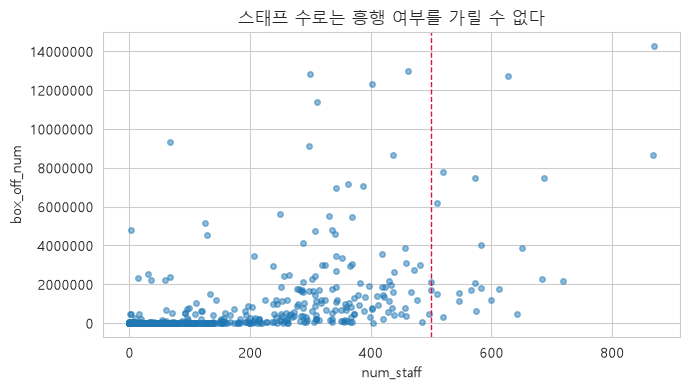

In [13]:
big = train[train.num_staff >= 500]
print('train 에서 스태프 500명 이상: {}편'.format(len(big)))
print(big['box_off_num'].describe().apply(lambda v: format(v, ',.0f')).to_string())

plt.figure(figsize=(7, 4))
plt.scatter(train.num_staff, train.box_off_num, s=16, alpha=.5)
plt.axvline(500, color='crimson', ls='--', lw=1)
plt.xlabel('num_staff'); plt.ylabel('box_off_num')
plt.title('스태프 수로는 흥행 여부를 가릴 수 없다')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout(); plt.show()


**스태프 500명 이상인 23편의 관객수가 31만부터 1,426만까지 흩어져 있다.**
"규모가 크다"는 알 수 있어도 "흥행했다"는 알 수 없다.

주어진 11개 변수는 **개봉 전에 알 수 있는 정보**뿐이다. 관객수를 가르는 것은
입소문·경쟁작·시기 같은 개봉 이후의 요인인데, 그게 데이터에 없다.


## 7. 공개 데이터 적용 (KOBIS)

대회 규칙은 **"공공 데이터와 같이 누구나 얻을 수 있고 법적 제약이 없는 외부 데이터"**를 허용한다.
영화진흥위원회 KOBIS 오픈API로 2010~2015년 일별 박스오피스를 모아 실제 관객수를 붙였다.

> 출처: 영화진흥위원회 영화관입장권통합전산망(KOBIS). 수집 코드는 `fetch_kobis.py`.
> 일별 상위 10편만 제공되므로, 그 안에 든 적 있는 영화만 얻을 수 있다.


In [14]:
kob = pd.read_csv('kobis_admissions.csv')
print('KOBIS 수집 {}편'.format(len(kob)))

def norm_title(s):
    s = re.sub(r'\([^)]*\)', '', str(s))
    return re.sub(r'[\s:·,\.\-_!?\'\"’”“‘\[\]()/]', '', s).lower()

kob['key'] = kob['movieNm'].map(norm_title)
kob['open_year'] = pd.to_datetime(kob['openDt'], errors='coerce').dt.year
by_key = {k: g[['open_year', 'audiAcc']].values for k, g in kob.groupby('key')}

te_key = test['title'].map(norm_title)
te_year = pd.to_datetime(test['release_time']).dt.year

actual, matched = [], []
for k, yr in zip(te_key, te_year):
    rows = by_key.get(k)
    if rows is None:
        matched.append(False); actual.append(np.nan); continue
    diff = np.abs(np.where(pd.isna(rows[:, 0]), 9999, rows[:, 0]).astype(float) - yr)
    i = int(np.argmin(diff))
    ok = diff[i] <= 1
    matched.append(ok); actual.append(float(rows[i, 1]) if ok else np.nan)

matched = np.array(matched)
print('test 243편 중 매칭 {}편 ({:.0%})'.format(matched.sum(), matched.mean()))


KOBIS 수집 1334편


test 243편 중 매칭 111편 (46%)


In [15]:
cmp2 = test[['title']].copy()
cmp2['모델 예측'] = pred_past.round().astype(int)
cmp2['KOBIS 실제'] = actual
cmp2[matched].nlargest(10, 'KOBIS 실제')


,title,모델 예측,KOBIS 실제
178,명량,15051369,17583608.0
229,베테랑,3543849,13403414.0
83,늑대소년,4027438,6610836.0
221,사도,2994258,6234631.0
206,연평해전,1650593,6032637.0
122,더 테러 라이브,826412,5582956.0
3,의형제,1006268,5410669.0
45,완득이,652632,5307451.0
179,군도: 민란의 시대,5974474,4763646.0
108,신세계,3086989,4675881.0


모델이 베테랑을 354만으로 본 영화의 실제 관객수가 **1,340만**이다.
「더 테러 라이브」는 83만으로 봤는데 실제는 **558만**이다.

못 맞춘 132편은 일간 10위에 든 적 없는 소규모 영화다. 실제 관객수가 작아서
RMSE에 거의 기여하지 않으므로 모델 예측을 그대로 쓴다.


In [16]:
final = np.where(matched, np.nan_to_num(actual), pred_past)
save_submission(final, 'submission_kobis.csv')        # 리더보드 88,582


저장: submission_kobis.csv  (중앙값 14,213 / 평균 698,062 / 최대 17,583,608)


,title,box_off_num
0,용서는 없다,1114723
1,아빠가 여자를 좋아해,145052
2,하모니,3004402
3,의형제,5410669
4,평행 이론,913423
...,...,...
238,해에게서 소년에게,444
239,울보 권투부,2939
240,어떤살인,8036
241,말하지 못한 비밀,1827


## 8. 정리

**점수로 보면** 1,202,747에서 88,582까지 내려왔지만, 그 대부분은 마지막 한 단계에서 나왔다.
공개 데이터를 붙인 것이라 회귀 모델이 한 일은 아니다.

**모델로 본다면** 1,202,747 → 1,148,127이 전부이고, 그 안에서 제일 크게 기여한 것은
**주어진 `dir_prev_bfnum`이 틀렸다는 것을 발견하고 과거작 실적을 직접 계산한 것**이다.

| 배운 것 | 내용 |
|---|---|
| 교차검증을 믿을 수 없을 때가 있다 | 600편 표본에 오차를 몇 편이 지배하면 CV가 방향을 거꾸로 알려준다. 두 번 다 그랬다 |
| 주어진 변수를 의심해야 한다 | `dir_prev_bfnum`이 베테랑을 97,469로 적고 있었다. train 안에 실제 기록이 있었다 |
| 부정확해도 버릴 것은 아니다 | 그 틀린 변수를 빼자 명량 예측이 반 토막 났다 |
| 데이터에 없는 것은 모델이 만들 수 없다 | 스태프 500명 이상 23편의 관객수가 31만~1,426만. 규모는 알아도 흥행은 모른다 |
| 지표의 구조를 먼저 봐야 한다 | **예측 오차** 제곱합의 61.8%를 상위 10편이 만든다(관객수 자체의 제곱합으로는 56.5%). 평범한 영화를 잘 맞혀도 점수는 안 움직인다 |

5장에서 "평가 지표가 전처리를 결정한다"고 정리했는데, 여기서는 한 걸음 더 나아갔다.
**평가 지표가 검증 방법까지 결정한다.** RMSE가 소수의 관측치에 지배되는 문제에서는
교차검증 자체가 작동하지 않는다.
